This notebook combines the judge-GOES results along wind trajectories and ACMCAP data for the analysis of closed-to-open cell transitions. To this end, we 
1. identify closed-to-open cell transitions in the judge-GOES results along trajectories, and
2. add the corresponding ACMCAP data for these transitioning clouds, using the pre-processed ACMCAP + judge-MSI dataset created in the previous notebook.

The analysis-ready dataset is then saved as '/home/jmayer/ACI_research/Code/resources_mesoscale_structure/CO_transitions_EC_GOES.nc'.


In [57]:
import xarray as xr
import pandas as pd
import numpy as np

## Load judge-GOES along trajectories

In [87]:
#with xr.open_dataset('/home/jmayer/ACI_research/Code/resources_mesoscale_structure/bt_with_goes.nc') as ds:
#    bt_with_goes = ds.load()

with xr.open_dataset('/home/jmayer/ACI_research/Code/resources_mesoscale_structure/bt_with_goes_BT14.nc') as ds:
    bt_with_goes = ds.load()

In [88]:
bt_with_goes['goes_cat_at_ec_overpass'] = (bt_with_goes.sel(timestep=0).goes_cats)

In [89]:
bt_with_goes

<xarray.Dataset> Size: 81MB
Dimensions:                  (time_startpoint: 12920, timestep: 43)
Coordinates:
  * time_startpoint          (time_startpoint) datetime64[ns] 103kB 2024-08-0...
  * timestep                 (timestep) int64 344B -42 -40 -38 -36 ... 38 40 42
    orbit                    (time_startpoint) <U6 310kB '01009E' ... '08369E'
Data variables: (12/19)
    lat_traj                 (time_startpoint, timestep) float64 4MB nan ... nan
    lon_traj                 (time_startpoint, timestep) float64 4MB nan ... nan
    plev_traj                (time_startpoint, timestep) float64 4MB nan ... nan
    datetime_traj            (time_startpoint, timestep) datetime64[ns] 4MB N...
    goes_cats                (time_startpoint, timestep) float64 4MB nan ... nan
    goes_cert                (time_startpoint, timestep) float64 4MB nan ... nan
    ...                       ...
    goes_lat_mid             (time_startpoint, timestep) float64 4MB nan ... nan
    goes_BT14                (time_startpoint, timestep) float64 4MB nan ... nan
    goes_ice_flag_2          (time_startpoint, timestep) float64 4MB nan ... nan
    goes_lat_mid_2           (time_startpoint, timestep) float64 4MB nan ... nan
    goes_lon_mid_2           (time_startpoint, timestep) float64 4MB nan ... nan
    goes_cat_at_ec_overpass  (time_startpoint) float64 103kB 1.0 1.0 ... 3.0 3.0

## clean up the dataset

In [90]:
# clean up the bt_with_goes dataset: convert a goes_cats value that is surrounded by goes_cats values of all the same category to that category, even if the middle value is different 
# 1, 1, 1      1, 1, 1
# 1, 3, 1  --> 1, 1, 1
# 1, 1, 1      1, 1, 1

bt_with_goes_cleaned = None
orbits = np.unique(bt_with_goes['orbit'])
for orbit in orbits:
    bt_orbit = bt_with_goes.where(bt_with_goes['orbit'] == orbit, drop=True)
    da = bt_orbit['goes_cats']

    neighbors = [
        da.shift(time_startpoint=-1, timestep=-1), da.shift(time_startpoint=-1, timestep=0), da.shift(time_startpoint=-1, timestep=1),
        da.shift(time_startpoint=0,  timestep=-1),                                           da.shift(time_startpoint=0,  timestep=1),
        da.shift(time_startpoint=1,  timestep=-1), da.shift(time_startpoint=1,  timestep=0), da.shift(time_startpoint=1,  timestep=1),
    ]

    stacked = xr.concat(neighbors, dim="neighbor")

    all_equal = (stacked == stacked.isel(neighbor=0)).all("neighbor")
    no_nan_neighbors = ~stacked.isnull().any("neighbor")
    center_diff = da != stacked.isel(neighbor=0)

    isolated_mask = all_equal & no_nan_neighbors & center_diff
    N_isolated = isolated_mask.sum().values

    surround_val = stacked.isel(neighbor=3)
    corrected = da.where(~isolated_mask, surround_val)
    bt_orbit['goes_cats_original'] = da
    bt_orbit['goes_cats'] = corrected

    if bt_with_goes_cleaned is None:
        bt_with_goes_cleaned = bt_orbit.copy()
    else:
        bt_with_goes_cleaned = xr.concat([bt_with_goes_cleaned, bt_orbit], dim='time_startpoint')
    print(f'Orbit {orbit}: {N_isolated} isolated points corrected')

    #fig, (ax0,ax1) = plt.subplots(1,2, figsize=(10,4))
    #da.T.plot(ax=ax0)
    #corrected.T.plot(ax=ax1)
    #fig.tight_layout()
    #plt.show()


Orbit 01009E: 1 isolated points corrected
Orbit 01024E: 1 isolated points corrected
Orbit 01040E: 0 isolated points corrected
Orbit 01056E: 0 isolated points corrected
Orbit 01071E: 1 isolated points corrected
Orbit 01087E: 0 isolated points corrected
Orbit 01102E: 0 isolated points corrected
Orbit 01133E: 0 isolated points corrected
Orbit 01164E: 1 isolated points corrected
Orbit 01180E: 0 isolated points corrected
Orbit 01195E: 0 isolated points corrected
Orbit 01211E: 0 isolated points corrected
Orbit 01227E: 0 isolated points corrected
Orbit 01242E: 0 isolated points corrected
Orbit 01258E: 0 isolated points corrected
Orbit 01273E: 1 isolated points corrected
Orbit 01289E: 1 isolated points corrected
Orbit 01304E: 0 isolated points corrected
Orbit 01320E: 0 isolated points corrected
Orbit 01335E: 0 isolated points corrected
Orbit 01351E: 1 isolated points corrected
Orbit 01367E: 0 isolated points corrected
Orbit 01382E: 1 isolated points corrected
Orbit 01398E: 0 isolated points co

In [91]:
# manual clean-up for few orbits, where we saw misclassifications of the CNN (some dissipating or forming clouds were classified as open cells):
# '01631E' # patch of dried out clouds? forming clouds?
# '02005E' # misclassification of the CNN
# '05848E' # dissipating clouds (instead of transitioning to open cells)
# '07575E' # patch of dry clouds? forming clouds? (only at latitudes -19 - -22)
# '07077E' # patch of dry clouds? forming clouds? (only at latitudes -19 - -22)
# '02518E' # patch of dry clouds? forming clouds? (only at latitudes -19 - -22)
# '06486E' # patch of dry clouds? forming clouds? (only at latitudes -19 - -22)
# '02518E' # patch of dry clouds? forming clouds? (only at latitudes -19 - -22)
# '06486E' # patch of dry clouds? forming clouds? (only at latitudes -19 - -22)
# '06719E' # patch of dry clouds? forming clouds? (only at latitudes -17 - -19)

bt_with_goes_cleaned['goes_cats'] = bt_with_goes_cleaned['goes_cats'].where(
                            (bt_with_goes_cleaned.orbit != '01631E') 
                            & (bt_with_goes_cleaned.orbit != '02005E') 
                            & (bt_with_goes_cleaned.orbit != '05848E') 
                            & ~((bt_with_goes_cleaned.orbit == '07575E') & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -19))
                            & ~((bt_with_goes_cleaned.orbit == '07077E') & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -19))
                            & ~((bt_with_goes_cleaned.orbit == '02518E') & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -19))
                            & ~((bt_with_goes_cleaned.orbit == '06486E') & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -19))
                            & ~((bt_with_goes_cleaned.orbit == '02518E') & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -19))
                            & ~((bt_with_goes_cleaned.orbit == '06486E') & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -19))
                            & ~((bt_with_goes_cleaned.orbit == '06719E') & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -17) & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj > -19))
                            , np.nan)

In [92]:
# manual clean-up by changing the goes_cats values in some orbits where we saw misclassifications by manual inspection

# CNN didnt detect some open cells 
bt_with_goes_cleaned['goes_cats'] = bt_with_goes_cleaned['goes_cats'].where(
        ~((bt_with_goes_cleaned.orbit == '01849E') 
        & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -9) 
        & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj > -11)
        & (bt_with_goes_cleaned.timestep >= -2) & (bt_with_goes_cleaned.timestep <= 4))
        , 2)
bt_with_goes_cleaned['goes_cats'] = bt_with_goes_cleaned['goes_cats'].where(
        ~((bt_with_goes_cleaned.orbit == '01849E') 
        & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -7.5) 
        & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj > -8)
        & (bt_with_goes_cleaned.timestep >= -4) & (bt_with_goes_cleaned.timestep <= 4))
        , 2)

# CNN didnt detect some open cells 
bt_with_goes_cleaned['goes_cats'] = bt_with_goes_cleaned['goes_cats'].where(
        ~((bt_with_goes_cleaned.orbit == '01009E') 
        & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -11.7) 
        & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj > -12.1)
        & (bt_with_goes_cleaned.timestep >= -4) & (bt_with_goes_cleaned.timestep <= 4))
        , 2)

# some dissipating/drying closed cells were wrongly categorised as open or disorganised
bt_with_goes_cleaned['goes_cats'] = bt_with_goes_cleaned['goes_cats'].where(
        ~((bt_with_goes_cleaned.orbit == '01382E') 
        & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -18) 
        & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj > -22)
        & (bt_with_goes_cleaned.timestep >= 0) & (~np.isnan(bt_with_goes_cleaned.goes_cats)))
        , 1)

# CNN didnt detect some open cells 
bt_with_goes_cleaned['goes_cats'] = bt_with_goes_cleaned['goes_cats'].where(
        ~((bt_with_goes_cleaned.orbit == '06501E') 
        & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -21) 
        & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj > -22)
        & (bt_with_goes_cleaned.timestep >= 15) & (~np.isnan(bt_with_goes_cleaned.goes_cats)))
        , 2)

# some open cells were detected too late
bt_with_goes_cleaned['goes_cats'] = bt_with_goes_cleaned['goes_cats'].where(
        ~((bt_with_goes_cleaned.orbit == '06501E') 
        & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -19.5) 
        & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj > -21)
        & (bt_with_goes_cleaned.timestep >= -2) & (bt_with_goes_cleaned.timestep <= 4))
        , 2)

# some open cells were detected one timestep too early
bt_with_goes_cleaned['goes_cats'] = bt_with_goes_cleaned['goes_cats'].where(
        ~((bt_with_goes_cleaned.orbit == '06050E') 
        & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -10.5) 
        & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj > -11.5)
        & (bt_with_goes_cleaned.timestep == 20))
        , 1)

In [93]:
bt_with_goes_cleaned

<xarray.Dataset> Size: 85MB
Dimensions:                  (time_startpoint: 12920, timestep: 43)
Coordinates:
  * time_startpoint          (time_startpoint) datetime64[ns] 103kB 2024-08-0...
  * timestep                 (timestep) int64 344B -42 -40 -38 -36 ... 38 40 42
    orbit                    (time_startpoint) <U6 310kB '01009E' ... '08369E'
Data variables: (12/20)
    lat_traj                 (time_startpoint, timestep) float64 4MB nan ... nan
    lon_traj                 (time_startpoint, timestep) float64 4MB nan ... nan
    plev_traj                (time_startpoint, timestep) float64 4MB nan ... nan
    datetime_traj            (time_startpoint, timestep) datetime64[ns] 4MB N...
    goes_cats                (time_startpoint, timestep) float64 4MB nan ... nan
    goes_cert                (time_startpoint, timestep) float64 4MB nan ... nan
    ...                       ...
    goes_BT14                (time_startpoint, timestep) float64 4MB nan ... nan
    goes_ice_flag_2          (time_startpoint, timestep) float64 4MB nan ... nan
    goes_lat_mid_2           (time_startpoint, timestep) float64 4MB nan ... nan
    goes_lon_mid_2           (time_startpoint, timestep) float64 4MB nan ... nan
    goes_cat_at_ec_overpass  (time_startpoint) float64 103kB 1.0 1.0 ... 3.0 3.0
    goes_cats_original       (time_startpoint, timestep) float64 4MB nan ... nan

## retrieve time to/from transitions

In [ ]:
def get_transition_properties(bt_dataset, transition_from_goes_cats=[2], transition_to_goes_cats=[1], backward=True, overwrite_existing_transitions=False):
    """
    Find where trajectories transition from cat0 to cat1 (e.g. open to closed cells)
    going backwards or forwards in time from timestep=0.
    
    Parameters:
    -----------
    bt_dataset : xarray.Dataset
        Dataset with goes_cats, datetime_traj variables
    transition_from_goes_cats : list
        List of MSI categories to transition from (default: [2])
    transition_to_goes_cats : list
        List of GOES categories to transition to (default: [0, 1])
    backward : bool
        Whether to search backwards in time (default: True)

    Returns:
    --------
    xarray.Dataset
        Dataset with added variables:
        - transition_flag: boolean flag indicating if transition occurred
        - transition_timestep: timestep where transition occurs (first stratiform point)
        - transition_datetime: datetime at transition (mean between last non-stratiform and first stratiform)
        - transition_time_diff: time difference from timestep=0 to transition
        - transition_uncertainty: time uncertainty of transition (half the time difference between last non-stratiform and first stratiform)
    """
    
    # Get dimensions
    n_startpoints = len(bt_dataset.time_startpoint)
    
    # Initialize arrays for results
    transition_flag = np.full(n_startpoints, False)
    transition_timestep = np.full(n_startpoints, np.nan)
    transition_datetime = np.full(n_startpoints, np.datetime64('NaT'), dtype='datetime64[ns]')
    transition_time_diff = np.full(n_startpoints, np.timedelta64('NaT'), dtype='timedelta64[ns]')
    transition_uncertainty = np.full(n_startpoints, np.timedelta64('NaT'), dtype='timedelta64[ns]')
    
    # Get timesteps sorted from 0 to negative values
    timesteps = bt_dataset.timestep.values
    if backward:
        timesteps_sorted = np.sort(timesteps)[::-1]  # Descending order: 0, -1, -2, ...
    else:
        timesteps_sorted = np.sort(timesteps)  # Ascending order: 0, 1, 2, ...
    
    for i in range(n_startpoints):
        traj = bt_dataset.isel(time_startpoint=i)

        # Check if the trajectory has already been flagged for transition
        if not overwrite_existing_transitions and ('transition_flag' in traj) and (traj.transition_flag.values == True):
            #print('Trajectory already flagged for transition, skipping...')
            transition_flag[i] = traj.transition_flag.values
            transition_timestep[i] = traj.transition_timestep.values
            transition_datetime[i] = traj.transition_datetime.values
            # convert traj.transition_time_diff and traj.transition_uncertainty to timedelta64 (otherwise they are stored as floats in hours, which causes issues when trying to combine with newly calculated transition_time_diff and transition_uncertainty values that are in timedelta64 format)
            transition_time_diff[i] = np.timedelta64(int(traj.transition_time_diff.values), 'h')
            transition_uncertainty[i] = np.timedelta64(int(traj.transition_uncertainty.values), 'h')
            continue  # Skip if already flagged for transition
        
        # Check if timestep=0 has the correct goes category to start from
        goes_cat_at_zero = float(traj.sel(timestep=0).goes_cats.values)
        if goes_cat_at_zero not in transition_from_goes_cats:
            continue  # Skip if not starting from desired GOES category
        
        # Get the datetime at timestep=0 for reference
        reference_datetime = traj.sel(timestep=0).datetime_traj.values
            
        # Look through timesteps from 0 backwards to find transition
        last_cat0_timestep = None
        last_cat0_datetime = None
        first_cat1_timestep = None
        first_cat1_datetime = None
        
        for timestep in timesteps_sorted:
            if backward and timestep > 0:
                continue  # Only look at timestep=0 and negative values
            elif not backward and timestep < 0:
                continue  # Only look at timestep=0 and positive values
                
            try:
                cats_value = float(traj.sel(timestep=timestep).goes_cats.values)
                
                # Skip if NaN
                if pd.isna(cats_value):
                    continue
                
                # If still in the from category, keep looking
                if cats_value in transition_from_goes_cats:
                    # update last cat0
                    last_cat0_timestep = timestep
                    last_cat0_datetime = traj.sel(timestep=timestep).datetime_traj.values
                # If the cat value has changed (i.e. clouds have transitioned)
                elif cats_value not in transition_from_goes_cats:
                    # Check if the clouds at timestep are cat1
                    if cats_value in transition_to_goes_cats:
                        first_cat1_timestep = timestep
                        first_cat1_datetime = traj.sel(timestep=timestep).datetime_traj.values
                        break
                    else:
                        # Transition to an unexpected category, stop searching
                        break  
                    
            except (KeyError, ValueError):
                continue  # Skip if timestep doesn't exist or other errors
        
        # If we found a transition, calculate the mean time and uncertainty
        if (first_cat1_timestep is not None and 
            last_cat0_timestep is not None and 
            first_cat1_datetime is not None and 
            last_cat0_datetime is not None):
            
            # Convert to pandas datetime for easier arithmetic
            first_strat_dt = pd.to_datetime(first_cat1_datetime)
            last_non_strat_dt = pd.to_datetime(last_cat0_datetime)
            ref_dt = pd.to_datetime(reference_datetime)
            
            # Calculate mean time between last non-stratiform and first stratiform
            mean_transition_time = last_non_strat_dt + (first_strat_dt - last_non_strat_dt) / 2
            
            # Calculate uncertainty (half the time difference between the two points)
            uncertainty = np.abs(first_strat_dt - last_non_strat_dt) / 2
            
            # Calculate time difference from timestep=0 to mean transition time
            time_diff_to_transition = ref_dt - mean_transition_time


            # if transition is during the night (i.e. last cat on day0 is cat0, and first cat on day1 is cat1), BT14 is used as an indicator of the exact transition time
            transition_during_night = (uncertainty > pd.Timedelta(hours=3))
            if transition_during_night and traj.sel(timestep=0).goes_BT14.values is not np.nan:
                # all BT14 values during the night should be between the last cat0 and first cat1 timesteps, so we can use them to find the transition time more precisely
                timesteps_during_night = slice(last_cat0_timestep, first_cat1_timestep) if not backward else slice(first_cat1_timestep, last_cat0_timestep)
                BT14_during_night = traj.sel(timestep=timesteps_during_night).goes_BT14
                ice_flag_during_night = traj.sel(timestep=timesteps_during_night).goes_ice_flag.fillna(0)
                if np.any(ice_flag_during_night > 0.05) or np.any(BT14_during_night < 277):
                    BT14_during_night = BT14_during_night.where((ice_flag_during_night < 0.05) & (BT14_during_night >= 277)) # only consider BT14 values where there are no ice clouds and BT14 is above 277K (i.e. 273 with a little wiggle room), as they obscure the view of the low-level clouds and thus the BT14 values are not indicative of the cloud break-up in those cases
                    # xarray DataArray example (fill NaN along 'timestep')
                    BT14_during_night = BT14_during_night.interpolate_na(dim="timestep", method="linear")
                    
                # find the timestep where BT14 increases most drastically, which should indicate the transition time (cloud break-up should lead to higher BT14 values)
                BT14_diff = (BT14_during_night.diff(dim='timestep'))
                if len(BT14_diff) > 0 and not np.all(np.isnan(BT14_diff.values)):
                    idx_max_diff = BT14_diff.argmax()
                    last_cat0_timestep = BT14_diff['timestep'][idx_max_diff-1].values
                    first_cat1_timestep = BT14_diff['timestep'][idx_max_diff].values
                    last_cat0_datetime = traj.sel(timestep=last_cat0_timestep).datetime_traj.values
                    first_cat1_datetime = traj.sel(timestep=first_cat1_timestep).datetime_traj.values
                    # update mean_transition_time and time_diff_to_transition to the time corresponding to the max BT14 change
                    mean_transition_time = pd.to_datetime(last_cat0_datetime) + (pd.to_datetime(first_cat1_datetime) - pd.to_datetime(last_cat0_datetime)) / 2
                    time_diff_to_transition = ref_dt - mean_transition_time
                        
                
            
            # Store results
            transition_flag[i] = True
            transition_timestep[i] = first_cat1_timestep
            transition_datetime[i] = mean_transition_time.to_numpy().astype('datetime64[ns]')
            transition_time_diff[i] = time_diff_to_transition.to_numpy().astype('timedelta64[h]') # make sure that this has the same unit as already existing transition_time_diff values, which are in hours
            transition_uncertainty[i] = uncertainty.to_numpy().astype('timedelta64[h]') 
    
    # Add results to dataset
    result = bt_dataset.copy()
    result['transition_flag'] = xr.DataArray(transition_flag, dims='time_startpoint')
    result['transition_timestep'] = xr.DataArray(transition_timestep, dims='time_startpoint')
    result['transition_datetime'] = xr.DataArray(transition_datetime, dims='time_startpoint')
    result['transition_time_diff'] = xr.DataArray(transition_time_diff, dims='time_startpoint')
    result['transition_uncertainty'] = xr.DataArray(transition_uncertainty, dims='time_startpoint')
    result['transition_time_diff'] = result.transition_time_diff.dt.total_seconds() / 3600 # save as a float in hours instead of a timedelta
    result['transition_uncertainty'] = result.transition_uncertainty.dt.total_seconds() / 3600

    # Add attributes
    result['transition_flag'].attrs = {'description': f'Boolean flag indicating if transition from cats = {transition_from_goes_cats} to cats = {transition_to_goes_cats} occurred'}
    result['transition_timestep'].attrs = {'description': f'Timestep where transition from cats = {transition_from_goes_cats} to cats = {transition_to_goes_cats} occurs (timestep of first cats = {transition_to_goes_cats} point)'}
    result['transition_datetime'].attrs = {'description': f'Mean datetime at transition point (mean between last cats = {transition_from_goes_cats} and first cats = {transition_to_goes_cats})'}
    result['transition_time_diff'].attrs = {'description': f'Time difference between EarthCARE overpass (timestep=0) and transition time ("transition_datetime") in hours (negative means transition is after overpass; positive means transition is earlier than overpass)'}
    result['transition_uncertainty'].attrs = {'description': f'Uncertainty in transition time in hours (half the time between last cats = {transition_from_goes_cats} and first cats = {transition_to_goes_cats})'}
    
    return result

In [137]:
# Apply to your open cell trajectories
bt_O = bt_with_goes_cleaned#.where(bt_with_goes_cleaned.goes_cat_at_ec_overpass == 2, drop=True)
bt_co = get_transition_properties(bt_O, transition_from_goes_cats=[2], transition_to_goes_cats=[1], backward=True, overwrite_existing_transitions=True)
# Check results
print("Transition statistics C -> O backwards from O:")
print(f"Trajectories with transitions: {(~pd.isna(bt_co.transition_timestep.values)).sum()}")
print(f"Total trajectories: {len(bt_co.time_startpoint)}")

#bt_C = bt_with_goes_cleaned#.where(bt_with_goes_cleaned.goes_cat_at_ec_overpass == 1, drop=True)
bt_co = get_transition_properties(bt_co, transition_from_goes_cats=[1], transition_to_goes_cats=[2], backward=False, overwrite_existing_transitions=False)
# Check results
print("Transition statistics C -> O forwards from C:")
print(f"Trajectories with transitions: {(~pd.isna(bt_co.transition_timestep.values)).sum()}")
print(f"Total trajectories: {len(bt_co.time_startpoint)}")

Transition statistics C -> O backwards from O:
Trajectories with transitions: 536
Total trajectories: 12920
Transition statistics C -> O forwards from C:
Trajectories with transitions: 983
Total trajectories: 12920


### check transition detection visually

In [139]:
bt_co#_back_from_o

<xarray.Dataset> Size: 85MB
Dimensions:                  (time_startpoint: 12920, timestep: 43)
Coordinates:
  * time_startpoint          (time_startpoint) datetime64[ns] 103kB 2024-08-0...
  * timestep                 (timestep) int64 344B -42 -40 -38 -36 ... 38 40 42
    orbit                    (time_startpoint) <U6 310kB '01009E' ... '08369E'
Data variables: (12/25)
    lat_traj                 (time_startpoint, timestep) float64 4MB nan ... nan
    lon_traj                 (time_startpoint, timestep) float64 4MB nan ... nan
    plev_traj                (time_startpoint, timestep) float64 4MB nan ... nan
    datetime_traj            (time_startpoint, timestep) datetime64[ns] 4MB N...
    goes_cats                (time_startpoint, timestep) float64 4MB nan ... nan
    goes_cert                (time_startpoint, timestep) float64 4MB nan ... nan
    ...                       ...
    goes_cats_original       (time_startpoint, timestep) float64 4MB nan ... nan
    transition_flag          (time_startpoint) bool 13kB False False ... False
    transition_timestep      (time_startpoint) float64 103kB nan nan ... nan nan
    transition_datetime      (time_startpoint) datetime64[ns] 103kB NaT ... NaT
    transition_time_diff     (time_startpoint) float64 103kB nan nan ... nan nan
    transition_uncertainty   (time_startpoint) float64 103kB nan nan ... nan nan

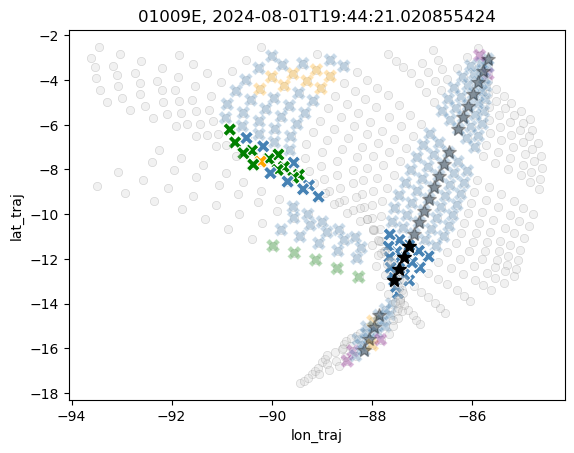

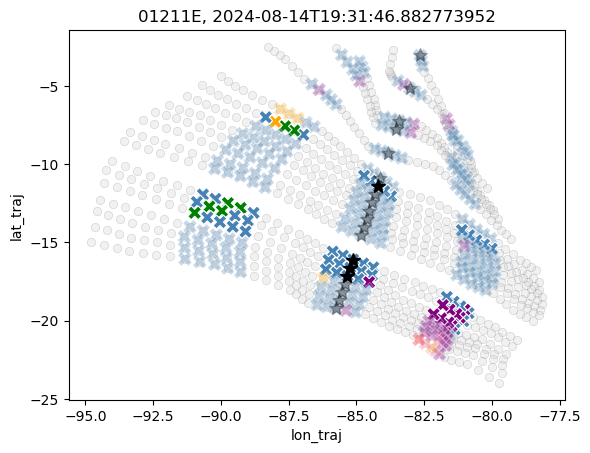

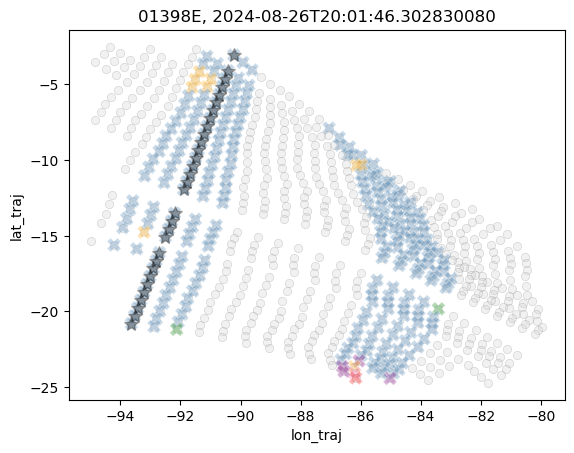

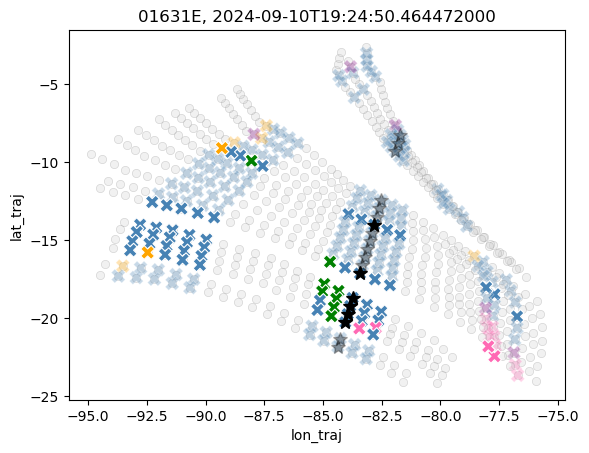

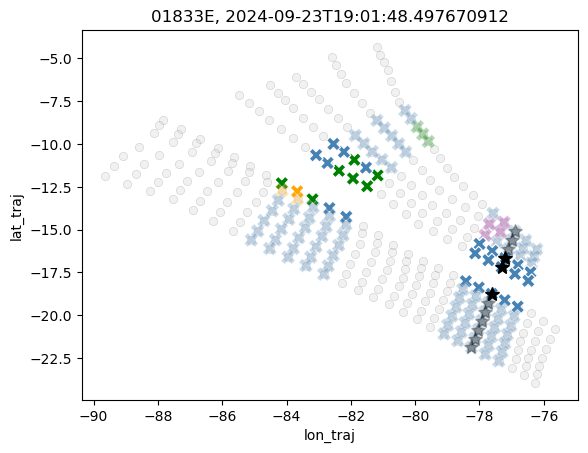

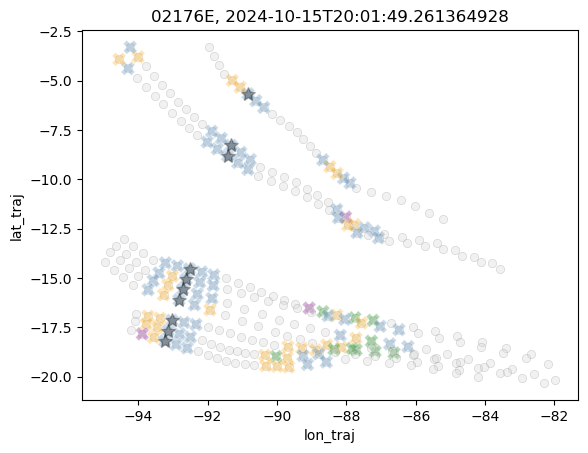

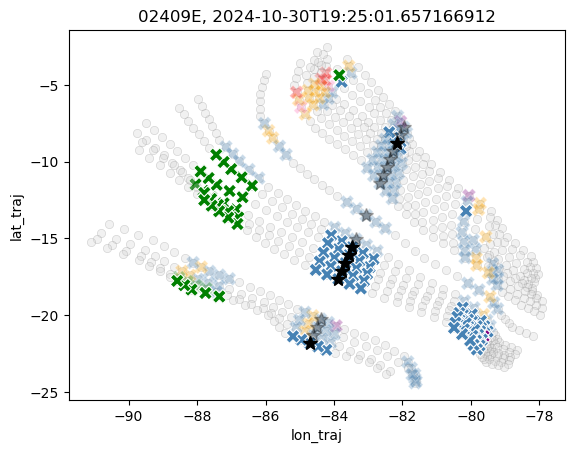

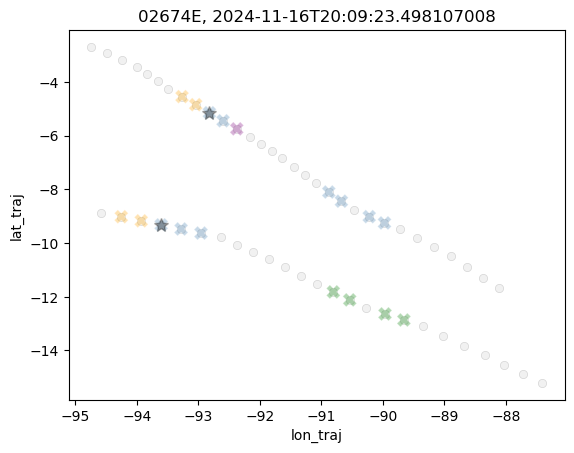

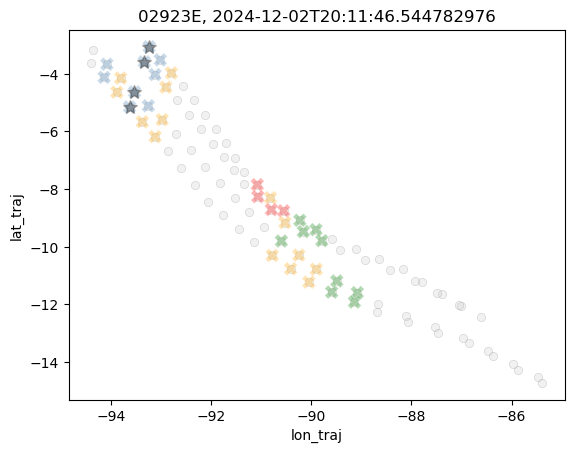

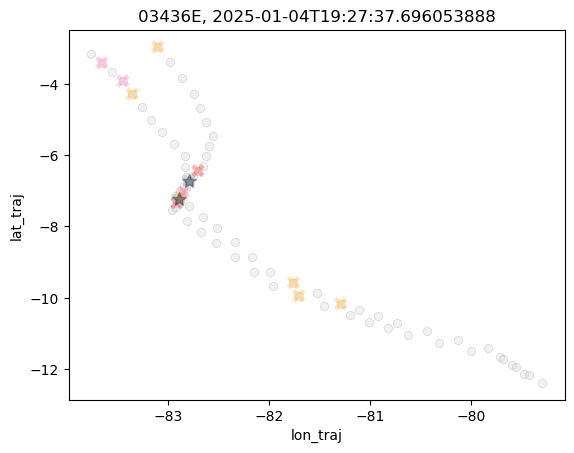

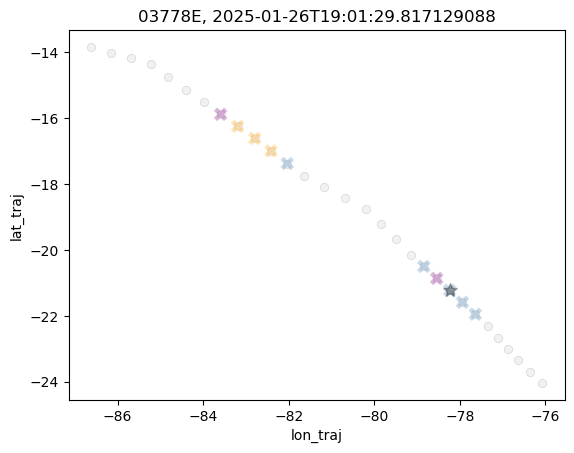

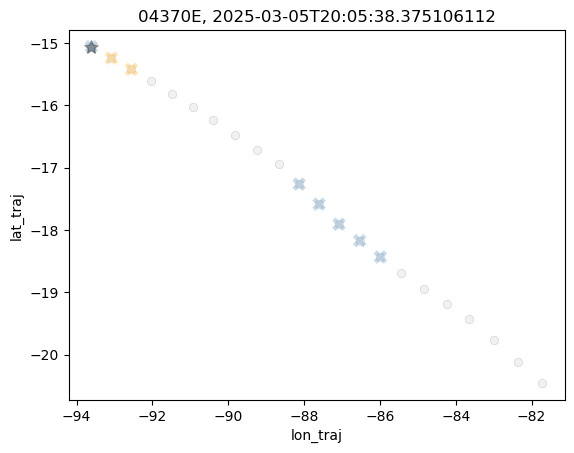

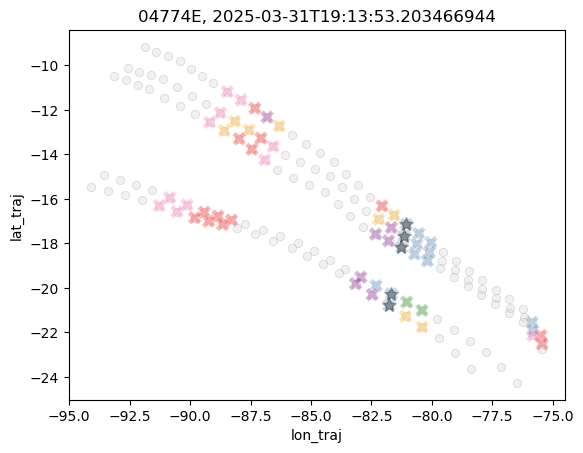

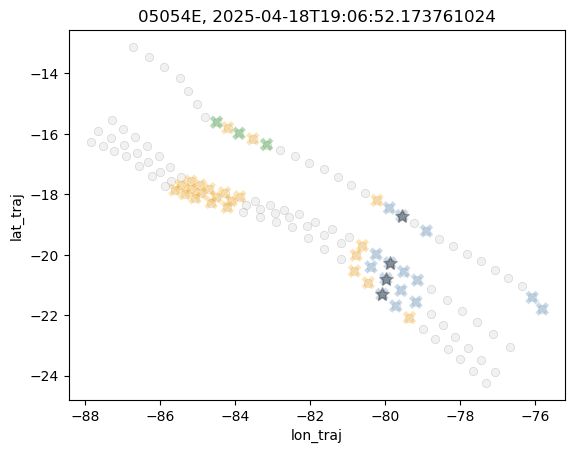

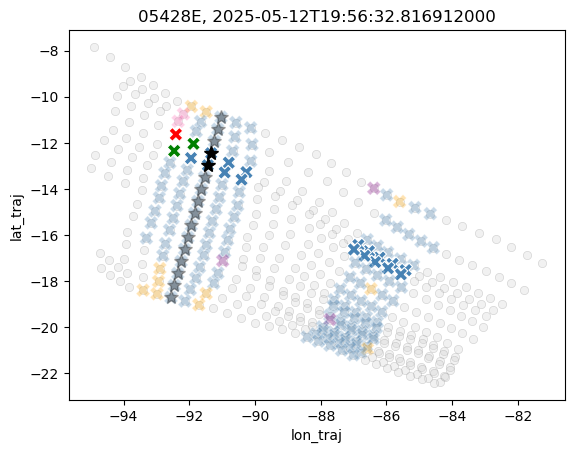

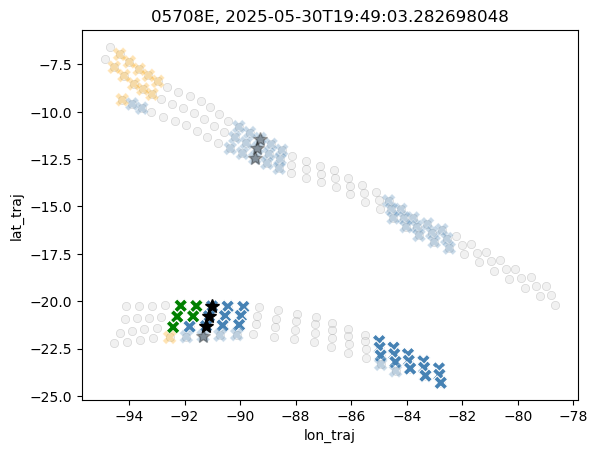

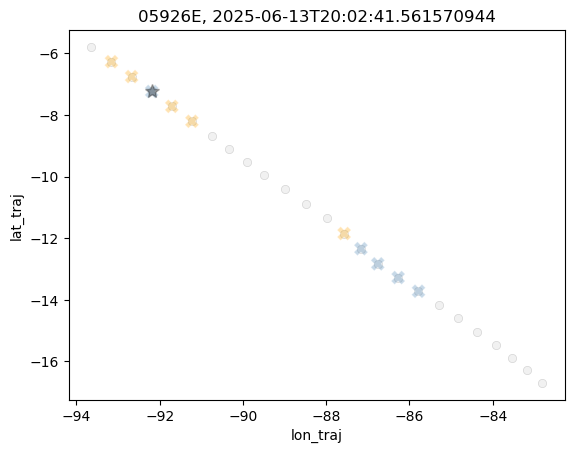

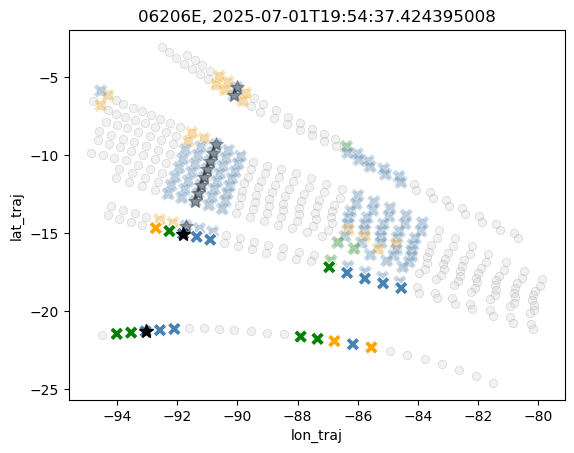

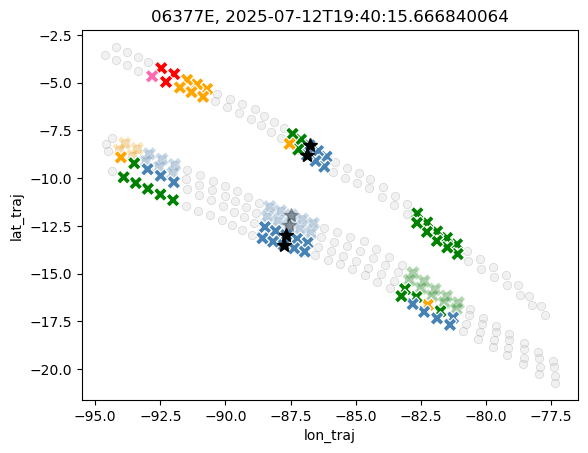

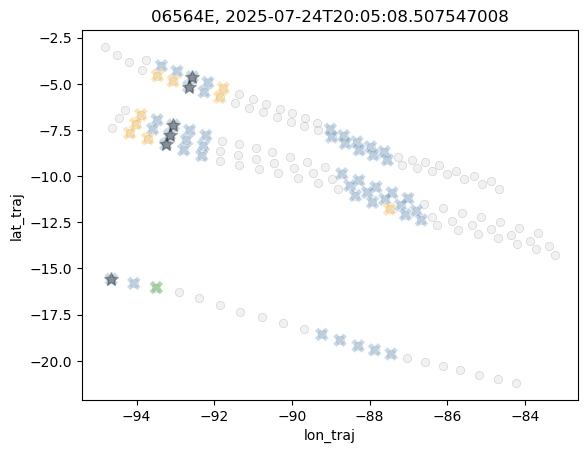

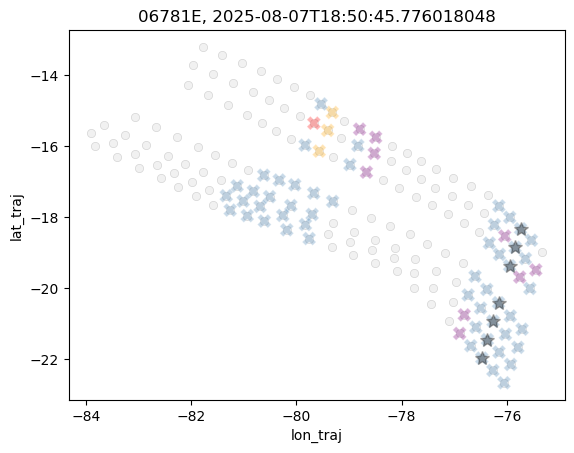

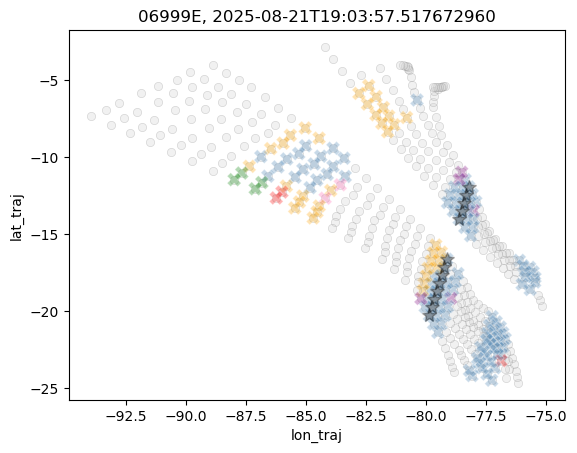

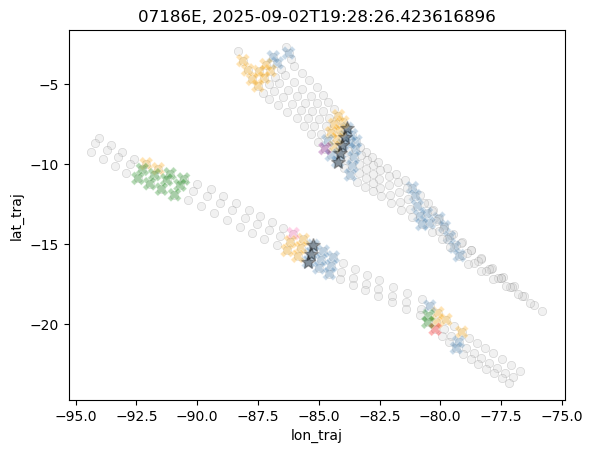

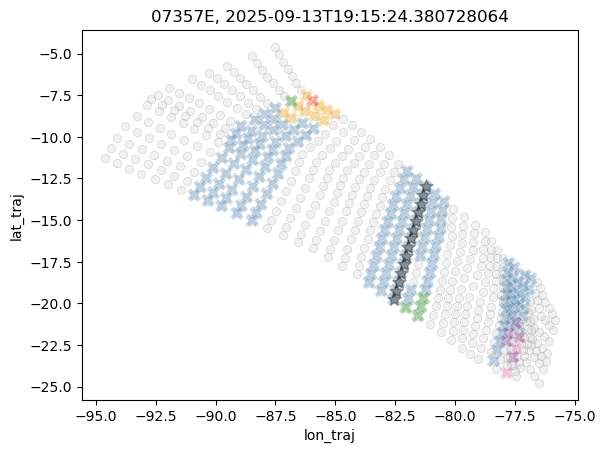

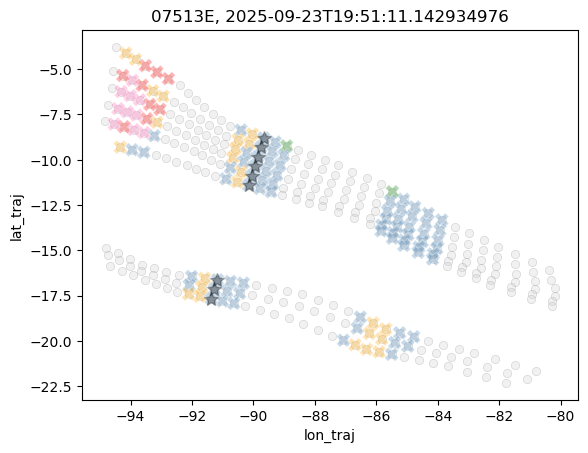

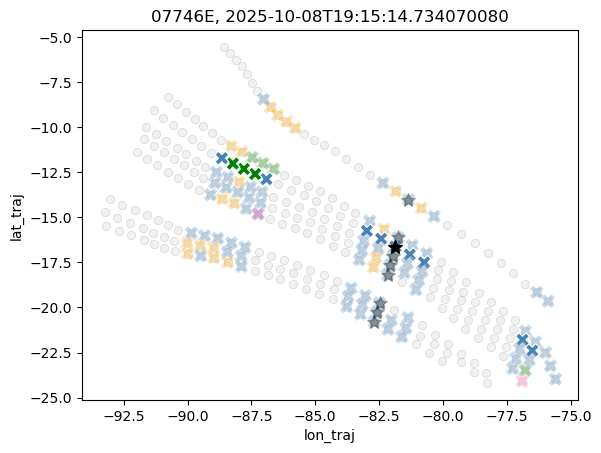

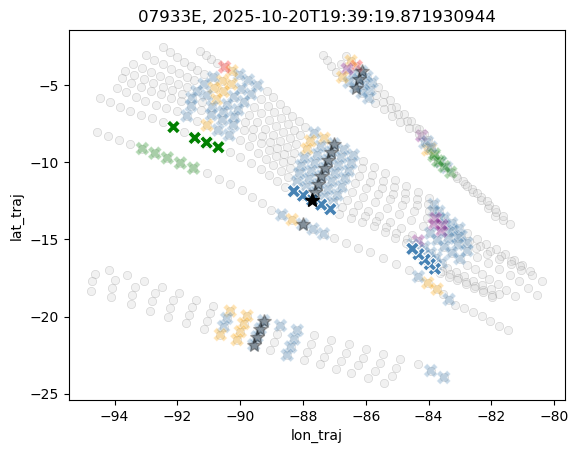

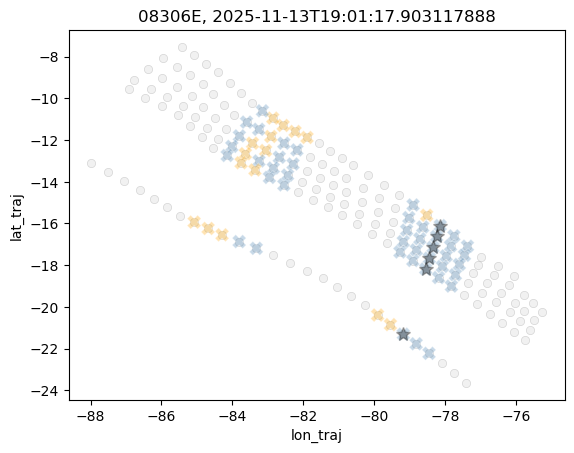

In [ ]:
palette_goes_cats = {0: 'purple', 1: 'steelblue', 2: 'green', 3: 'orange', 4: 'red', 5: 'hotpink', np.nan: 'grey'}

ds_to_check = bt_co #bt_co_back_from_o

for orbit in np.unique(ds_to_check.orbit)[::10]:
    bt_orbit = ds_to_check.where(ds_to_check.orbit == orbit, drop=True)
    for i in range(len(bt_orbit.time_startpoint)):
        tmp = bt_orbit.isel(time_startpoint=i)
        if tmp.transition_flag == False:
            # no transition detected
            alpha = 0.3
        else:
            # transition detected
            alpha = 1.0
        sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', color='lightgrey', alpha=0.3, edgecolor='Grey', legend=False)
        plt.plot([tmp.sel(timestep=0).lon_traj.values], [tmp.sel(timestep=0).lat_traj.values], color='black', marker='*', markersize=10, alpha=alpha)
        sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
    plt.title(f'{orbit}, {bt_orbit.time_startpoint.values[0]}')
    plt.show()

## add ACMCAP information

In [140]:
acmcap_dataset_filename = '/home/jmayer/ACI_research/Code/resources_mesoscale_structure/ACMCAP_judge_StCu.h5'
acmcap = pd.read_hdf(acmcap_dataset_filename, key='StCu')

# only need SEP data
acmcap = acmcap[acmcap.stratus_region_index == 2]

ds_acmcap = acmcap.to_xarray()
ds_acmcap = ds_acmcap.rename({'time_mid':'time_startpoint'})
ds_acmcap = ds_acmcap.swap_dims({'index':'time_startpoint'})
ds_acmcap = ds_acmcap.assign_coords({
    'time_startpoint': ds_acmcap.time_startpoint.values,
    'orbit': ('time_startpoint', ds_acmcap.orbit.values)})
ds_acmcap = ds_acmcap.drop_vars(['index'])

ds_acmcap['time_startpoint'] = ds_acmcap.time_startpoint.dt.round('0.1s')
ds_acmcap = ds_acmcap.assign_coords({'timestep': ('timestep', [0])})

ds_acmcap

<xarray.Dataset> Size: 11MB
Dimensions:                               (time_startpoint: 12979, timestep: 1)
Coordinates:
    orbit                                 (time_startpoint) object 104kB '010...
  * time_startpoint                       (time_startpoint) datetime64[ns] 104kB ...
  * timestep                              (timestep) int64 8B 0
Data variables: (12/106)
    scene_id                              (time_startpoint) int64 104kB 25868...
    stratus_region_index                  (time_startpoint) int64 104kB 2 ... 2
    along_track_mid                       (time_startpoint) float64 104kB 128...
    lon_mid                               (time_startpoint) float64 104kB -85...
    lat_mid                               (time_startpoint) float64 104kB -3....
    lat_min                               (time_startpoint) float64 104kB -3....
    ...                                    ...
    rwc_cbh_perc75                        (time_startpoint) float64 104kB nan...
    rwc_cbh_perc95                        (time_startpoint) float64 104kB nan...
    rwc_cbh_perc05                        (time_startpoint) float64 104kB nan...
    rain_gini                             (time_startpoint) float64 104kB 0.0...
    rain_lcf                              (time_startpoint) float64 104kB 0.0...
    rain_n_clusters                       (time_startpoint) int64 104kB 0 ... 3

In [141]:
ds_acmcap['rain_fraction_no_zero'] = ds_acmcap['rain_fraction'].where(ds_acmcap['rain_fraction'] != 0, np.nan)
for var in ['cbh_m', 'cth_m', 'lwp', 'ER', 'Nd', 'rwp', 'rain_median_volume_diameter']:
    ds_acmcap[var+'_cv'] = ds_acmcap[var+'_std'] / ds_acmcap[var]
acmcap_climatology_median = ds_acmcap.where(ds_acmcap.cats.isin([1,2]), drop=True).groupby('cats').median()
acmcap_climatology_std = ds_acmcap.where(ds_acmcap.cats.isin([1,2]), drop=True).groupby('cats').std()

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension cats because variable cats is not a coordinate. To create an index for cats, please first call `.set_coords('cats')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension cats because variable cats is not a coordinate. To create an index for cats, please first call `.set_coords('cats')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


In [142]:
bt_co['time_startpoint'] = bt_co.time_startpoint.dt.round('0.1s')

# Align datasets along common dimensions first
bt_aligned, acmcap_aligned = xr.align(bt_co, ds_acmcap, join='left')

# Then merge
bt_co = bt_aligned.merge(acmcap_aligned)

In [143]:
bt_co

<xarray.Dataset> Size: 97MB
Dimensions:                               (time_startpoint: 12920, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 103kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 103kB '010...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 4MB ...
    lon_traj                              (time_startpoint, timestep) float64 4MB ...
    plev_traj                             (time_startpoint, timestep) float64 4MB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 4MB ...
    goes_cats                             (time_startpoint, timestep) float64 4MB ...
    goes_cert                             (time_startpoint, timestep) float64 4MB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 103kB 0.0...
    lwp_cv                                (time_startpoint) float64 103kB 0.5...
    ER_cv                                 (time_startpoint) float64 103kB 0.3...
    Nd_cv                                 (time_startpoint) float64 103kB 0.3...
    rwp_cv                                (time_startpoint) float64 103kB nan...
    rain_median_volume_diameter_cv        (time_startpoint) float64 103kB nan...

### filter trajectories: cat_GOES == cat_MSI

In [144]:
# GOES CNN category at overpass should be the same as MSI category
bt_co = bt_co.where(bt_co.goes_cats.sel(timestep=0).drop('timestep') == bt_co.cats, drop=True)

/tmp/ipykernel_174345/2609147007.py:2: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  bt_co = bt_co.where(bt_co.goes_cats.sel(timestep=0).drop('timestep') == bt_co.cats, drop=True)


In [145]:
bt_co.to_netcdf('/home/jmayer/ACI_research/Code/resources_mesoscale_structure/CO_transitions_EC_GOES_2.nc')

In [146]:
bt_co

<xarray.Dataset> Size: 49MB
Dimensions:                               (time_startpoint: 6544, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 52kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 52kB '0100...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 2MB ...
    lon_traj                              (time_startpoint, timestep) float64 2MB ...
    plev_traj                             (time_startpoint, timestep) float64 2MB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 2MB ...
    goes_cats                             (time_startpoint, timestep) float64 2MB ...
    goes_cert                             (time_startpoint, timestep) float64 2MB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 52kB 0.09...
    lwp_cv                                (time_startpoint) float64 52kB 0.53...
    ER_cv                                 (time_startpoint) float64 52kB 0.22...
    Nd_cv                                 (time_startpoint) float64 52kB 0.30...
    rwp_cv                                (time_startpoint) float64 52kB 8.77...
    rain_median_volume_diameter_cv        (time_startpoint) float64 52kB 0.19...

In [148]:
bt_co.where(bt_co.transition_flag == True, drop=True)

<xarray.Dataset> Size: 6MB
Dimensions:                               (time_startpoint: 803, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 6kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 6kB '01009...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 276kB ...
    lon_traj                              (time_startpoint, timestep) float64 276kB ...
    plev_traj                             (time_startpoint, timestep) float64 276kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 276kB ...
    goes_cats                             (time_startpoint, timestep) float64 276kB ...
    goes_cert                             (time_startpoint, timestep) float64 276kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 6kB 0.201...
    lwp_cv                                (time_startpoint) float64 6kB 1.009...
    ER_cv                                 (time_startpoint) float64 6kB 0.481...
    Nd_cv                                 (time_startpoint) float64 6kB 1.087...
    rwp_cv                                (time_startpoint) float64 6kB 20.38...
    rain_median_volume_diameter_cv        (time_startpoint) float64 6kB 0.442...

In [149]:
bt_co.where((bt_co.transition_flag == True) & (bt_co.cats == 1), drop=True)

<xarray.Dataset> Size: 2MB
Dimensions:                               (time_startpoint: 330, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 3kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 3kB '01009...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 114kB ...
    lon_traj                              (time_startpoint, timestep) float64 114kB ...
    plev_traj                             (time_startpoint, timestep) float64 114kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 114kB ...
    goes_cats                             (time_startpoint, timestep) float64 114kB ...
    goes_cert                             (time_startpoint, timestep) float64 114kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 3kB 0.201...
    lwp_cv                                (time_startpoint) float64 3kB 1.009...
    ER_cv                                 (time_startpoint) float64 3kB 0.481...
    Nd_cv                                 (time_startpoint) float64 3kB 1.087...
    rwp_cv                                (time_startpoint) float64 3kB 20.38...
    rain_median_volume_diameter_cv        (time_startpoint) float64 3kB 0.442...

In [150]:
bt_co.where((bt_co.transition_flag == True) & (bt_co.cats == 2), drop=True)

<xarray.Dataset> Size: 4MB
Dimensions:                               (time_startpoint: 473, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 4kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 4kB '01040...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 163kB ...
    lon_traj                              (time_startpoint, timestep) float64 163kB ...
    plev_traj                             (time_startpoint, timestep) float64 163kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 163kB ...
    goes_cats                             (time_startpoint, timestep) float64 163kB ...
    goes_cert                             (time_startpoint, timestep) float64 163kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 4kB 0.156...
    lwp_cv                                (time_startpoint) float64 4kB 1.328...
    ER_cv                                 (time_startpoint) float64 4kB 0.538...
    Nd_cv                                 (time_startpoint) float64 4kB 0.830...
    rwp_cv                                (time_startpoint) float64 4kB 1.387...
    rain_median_volume_diameter_cv        (time_startpoint) float64 4kB 0.222...